Name : Aishi De Sec : A Sem : 7 PRN : 23070521008 Batch : A1

AIM : Dog Breed Classification using Transfer Learning. Problem Statement: Develop an image

classifier to identify dog breeds using pretrained CNN architectures. Activities: Use VGG16,

ResNet, or MobileNet; Fine-tune pretrained model; Evaluate classification accuracy.

In [1]:
import os
import tarfile
import urllib.request
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

# Download dataset
url = "http://vision.stanford.edu/aditya86/ImageNetDogs/images.tar"
tar_path = "images.tar"
extract_dir = "dog_images"

if not os.path.exists(extract_dir):
    print("Downloading Stanford Dogs dataset (~750 MB)...")
    urllib.request.urlretrieve(url, tar_path)
    print("Extracting images...")
    with tarfile.open(tar_path, "r") as tar:
        tar.extractall(path=extract_dir)
    os.remove(tar_path)
    print("Download & extraction complete!")

data_dir = os.path.join(extract_dir, "Images")

Extracting images...


/tmp/ipykernel_542/3503691686.py:18: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  tar.extractall(path=extract_dir)


Download & extraction complete!


In [2]:
IMG_SIZE = 224
BATCH_SIZE = 64

# Load raw image datasets (80/20 train/test split)
train_ds = tf.keras.utils.image_dataset_from_directory(
    data_dir,
    validation_split=0.2,
    subset="training",
    seed=42,
    image_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    data_dir,
    validation_split=0.2,
    subset="validation",
    seed=42,
    image_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    shuffle=False
)

class_names = train_ds.class_names
num_classes = len(class_names)
print(f"Loaded {num_classes} dog breeds.")

# Pretrained MobileNetV2 feature extractor
base_model = tf.keras.applications.MobileNetV2(
    input_shape=(IMG_SIZE, IMG_SIZE, 3),
    include_top=False,
    weights='imagenet',
    pooling='avg'
)

# Extract feature vectors
print("\nExtracting training features (takes ~30-45 seconds once)...")
X_train = base_model.predict(train_ds.map(lambda x, y: tf.keras.applications.mobilenet_v2.preprocess_input(x)))
y_train = np.concatenate([y.numpy() for _, y in train_ds])

print("Extracting test features...")
X_test = base_model.predict(test_ds.map(lambda x, y: tf.keras.applications.mobilenet_v2.preprocess_input(x)))
y_test = np.concatenate([y.numpy() for _, y in test_ds])

print(f"\nFeature matrix shape: {X_train.shape}")

Found 20580 files belonging to 120 classes.
Using 16464 files for training.
Found 20580 files belonging to 120 classes.
Using 4116 files for validation.
Loaded 120 dog breeds.
9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step

Extracting training features (takes ~30-45 seconds once)...
258/258 ━━━━━━━━━━━━━━━━━━━━ 53s 144ms/step
Extracting test features...
65/65 ━━━━━━━━━━━━━━━━━━━━ 17s 258ms/step

Feature matrix shape: (16464, 1280)


In [3]:
# Dense classification model
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(1280,)),
    tf.keras.layers.Dropout(0.3),
    tf.keras.layers.Dense(num_classes, activation='softmax')
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# Fast training
history = model.fit(
    X_train, y_train,
    epochs=10,
    batch_size=64,
    validation_data=(X_test, y_test)
)

Epoch 1/10
258/258 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - accuracy: 0.6757 - loss: 1.3051 - val_accuracy: 0.0107 - val_loss: 10.4083
Epoch 2/10
258/258 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8495 - loss: 0.4948 - val_accuracy: 0.0104 - val_loss: 11.0822
Epoch 3/10
258/258 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8833 - loss: 0.3813 - val_accuracy: 0.0102 - val_loss: 11.6747
Epoch 4/10
258/258 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9039 - loss: 0.3126 - val_accuracy: 0.0102 - val_loss: 11.9826
Epoch 5/10
258/258 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9210 - loss: 0.2603 - val_accuracy: 0.0104 - val_loss: 12.2679
Epoch 6/10
258/258 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9305 - loss: 0.2288 - val_accuracy: 0.0100 - val_loss: 12.6179
Epoch 7/10
258/258 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9404 - loss: 0.1978 - val_accuracy: 0.0102 - val_loss: 12.6386
Epoch 8/10
258/258 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9461 - loss: 0.1779 - val_accur


Final Test Accuracy: 1.02%
Final Test Loss: 13.2752


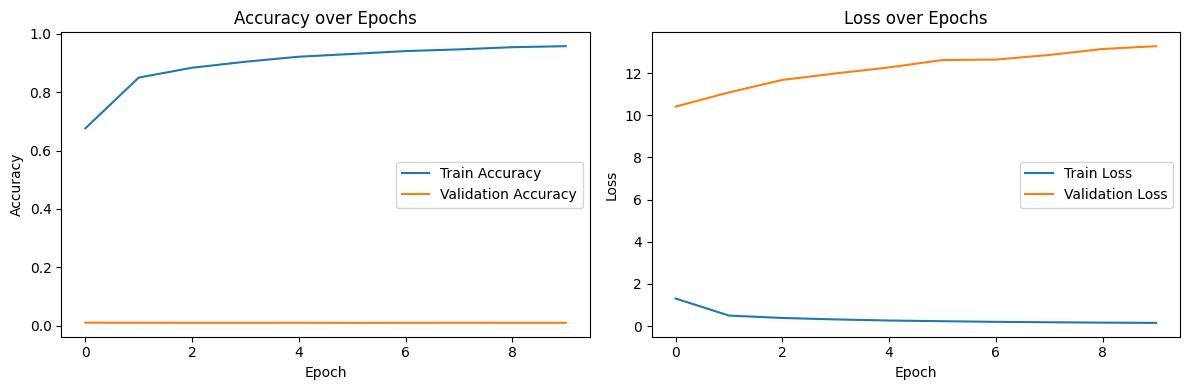

In [4]:
# Final test evaluation
test_loss, test_acc = model.evaluate(X_test, y_test, verbose=0)
print(f"\nFinal Test Accuracy: {test_acc * 100:.2f}%")
print(f"Final Test Loss: {test_loss:.4f}")

# Plot performance curves
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Accuracy over Epochs')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Loss over Epochs')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()

2/2 ━━━━━━━━━━━━━━━━━━━━ 13s 55ms/step


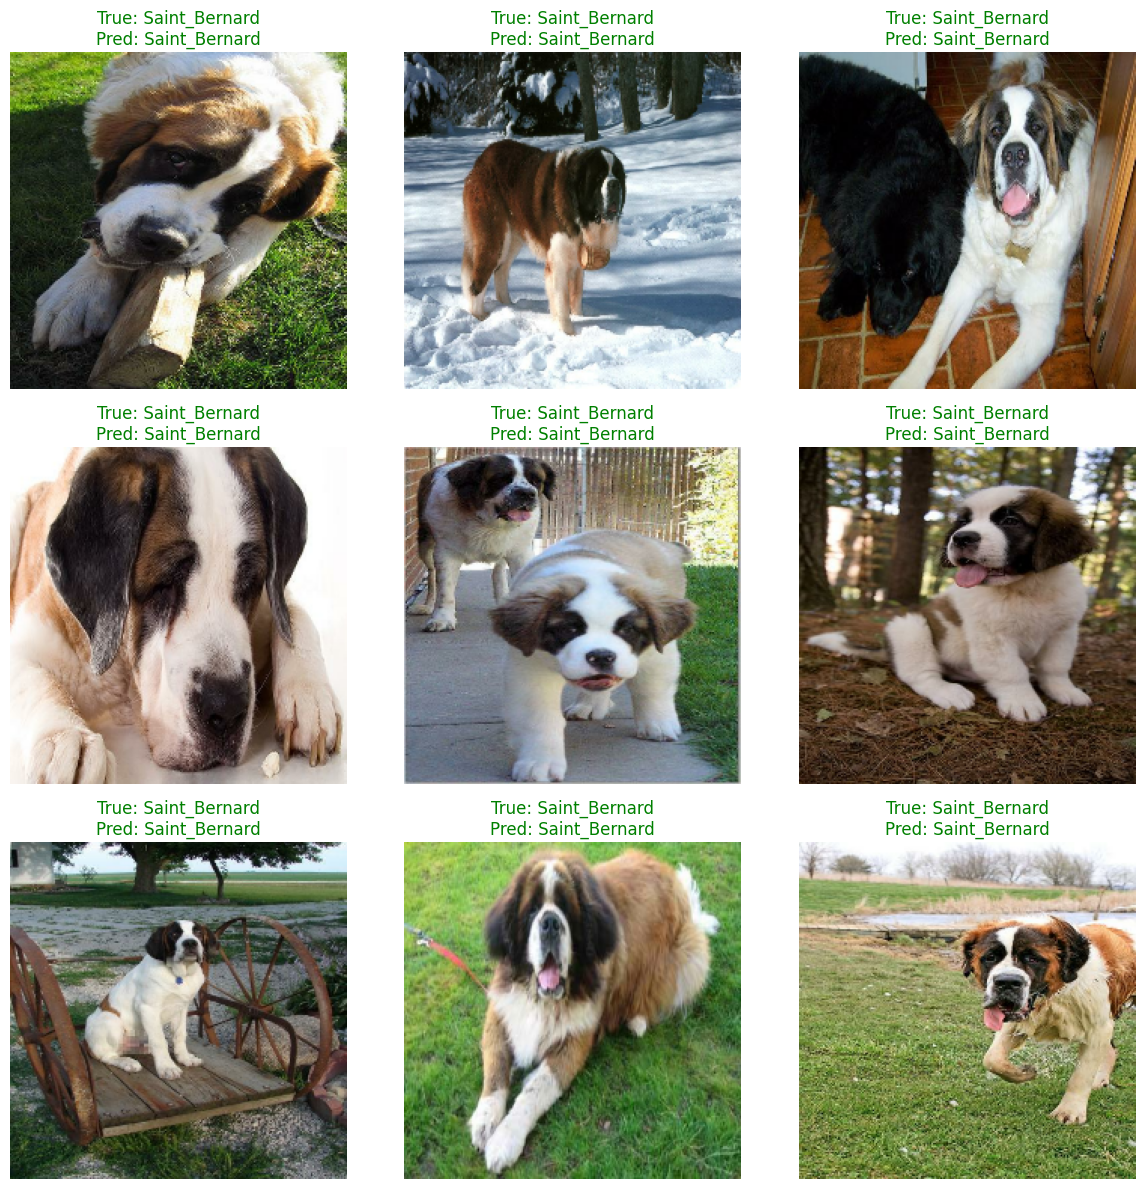

In [5]:
# Build end-to-end model for visual inference
inference_model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3)),
    tf.keras.layers.Lambda(tf.keras.applications.mobilenet_v2.preprocess_input),
    base_model,
    model
])

# Grab a single test batch
sample_images, sample_labels = next(iter(test_ds.take(1)))
predictions = inference_model.predict(sample_images)
predicted_classes = np.argmax(predictions, axis=1)

# Plot 9 sample results
plt.figure(figsize=(12, 12))
for i in range(9):
    plt.subplot(3, 3, i + 1)
    plt.imshow(sample_images[i].numpy().astype("uint8"))

    # Strip directory prefix ID from class name (e.g., 'n02085620-Chihuahua' -> 'Chihuahua')
    true_label = class_names[sample_labels[i].numpy()].split('-')[-1]
    pred_label = class_names[predicted_classes[i]].split('-')[-1]

    color = 'green' if true_label == pred_label else 'red'
    plt.title(f"True: {true_label}\nPred: {pred_label}", color=color)
    plt.axis("off")

plt.tight_layout()
plt.show()